In [9]:
%pip install numpy pandas matplotlib scikit-learn threadpoolctl

Note: you may need to restart the kernel to use updated packages.


In [10]:
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from threadpoolctl import threadpool_limits

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

from sklearn.neural_network import MLPClassifier, MLPRegressor

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

SEED = 42
MAX_EPOCHS = 350
PATIENCE = 35

np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 20)

Размер таблицы: (2126, 22)
Количество пропусков: 0
Количество дубликатов: 13


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


,count,mean,std,min,25%,50%,75%,max
baseline value,2113.0,133.305,9.837,106.0,126.000,133.000,140.000,160.000
accelerations,2113.0,0.003,0.004,0.0,0.000,0.002,0.006,0.019
fetal_movement,2113.0,0.010,0.047,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2113.0,0.004,0.003,0.0,0.002,0.005,0.007,0.015
light_decelerations,2113.0,0.002,0.003,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2113.0,0.000,0.000,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2113.0,0.000,0.001,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2113.0,46.994,17.178,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2113.0,1.335,0.884,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2113.0,9.795,18.337,0.0,0.000,0.000,11.000,91.000


,Количество,Доля
fetal_health,,
1,1646,0.778987
2,292,0.138192
3,175,0.082821


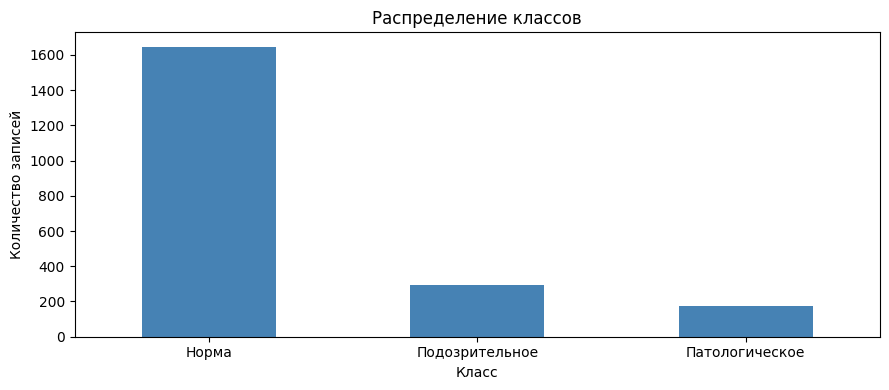

In [11]:
fetal = pd.read_csv("fetal_health.csv")

print("Размер таблицы:", fetal.shape)
print("Количество пропусков:", fetal.isna().sum().sum())
print("Количество дубликатов:", fetal.duplicated().sum())

display(fetal.head())

# Удаляем одинаковые записи до разделения выборки.
fetal = fetal.drop_duplicates().reset_index(drop=True)

display(fetal.describe().T.round(3))

class_names = {
    1: "Норма",
    2: "Подозрительное",
    3: "Патологическое"
}

classes = np.array([1, 2, 3])

counts = fetal["fetal_health"].astype(int).value_counts().sort_index()

display(pd.DataFrame({
    "Количество": counts,
    "Доля": counts / counts.sum()
}))

counts.rename(index=class_names).plot.bar(
    color="steelblue",
    rot=0
)

plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество записей")
plt.tight_layout()
plt.show()

In [12]:
X = fetal.drop(columns="fetal_health")
y = fetal["fetal_health"].astype(int)

Xc_train, Xc_rest, yc_train, yc_rest = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

Xc_val, Xc_test, yc_val, yc_test = train_test_split(
    Xc_rest,
    yc_rest,
    test_size=0.50,
    stratify=yc_rest,
    random_state=SEED
)

preprocessor_c = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

Xc_train = preprocessor_c.fit_transform(Xc_train)
Xc_val = preprocessor_c.transform(Xc_val)
Xc_test = preprocessor_c.transform(Xc_test)

yc_train = yc_train.to_numpy()
yc_val = yc_val.to_numpy()
yc_test = yc_test.to_numpy()

print("Обучение:", Xc_train.shape)
print("Валидация:", Xc_val.shape)
print("Тест:", Xc_test.shape)

Обучение: (1479, 21)
Валидация: (317, 21)
Тест: (317, 21)


In [13]:
configs = [
    {
        "name": "16_relu_adam",
        "layers": (16,),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_relu_adam",
        "layers": (32,),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "64_32_relu_adam",
        "layers": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_16_tanh_adam",
        "layers": (32, 16),
        "activation": "tanh",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.001
    },
    {
        "name": "32_16_relu_sgd",
        "layers": (32, 16),
        "activation": "relu",
        "solver": "sgd",
        "lr": 0.01,
        "alpha": 0.001
    },
    {
        "name": "64_32_16_relu_adam",
        "layers": (64, 32, 16),
        "activation": "relu",
        "solver": "adam",
        "lr": 0.001,
        "alpha": 0.01
    }
]

display(pd.DataFrame(configs))

,name,layers,activation,solver,lr,alpha
0,16_relu_adam,"(16,)",relu,adam,0.001,0.001
1,32_relu_adam,"(32,)",relu,adam,0.001,0.001
2,64_32_relu_adam,"(64, 32)",relu,adam,0.001,0.001
3,32_16_tanh_adam,"(32, 16)",tanh,adam,0.001,0.001
4,32_16_relu_sgd,"(32, 16)",relu,sgd,0.010,0.001
5,64_32_16_relu_adam,"(64, 32, 16)",relu,adam,0.001,0.010


In [14]:
def train_model(config, X_train, y_train, X_val, y_val, task):
    if task == "classification":
        model_class = MLPClassifier
    else:
        model_class = MLPRegressor

    model = model_class(
        hidden_layer_sizes=config["layers"],
        activation=config["activation"],
        solver=config["solver"],
        learning_rate_init=config["lr"],
        learning_rate="constant",
        alpha=config["alpha"],
        batch_size=64,
        momentum=0.9,
        shuffle=True,
        early_stopping=False,
        random_state=SEED,
        max_iter=1
    )

    history = []
    best_loss = np.inf
    best_model = None
    best_epoch = 0
    waiting = 0

    with threadpool_limits(limits=1):
        for epoch in range(1, MAX_EPOCHS + 1):
            if task == "classification":
                model.partial_fit(
                    X_train,
                    y_train,
                    classes=classes
                )

                train_loss = log_loss(
                    y_train,
                    model.predict_proba(X_train),
                    labels=classes
                )

                val_loss = log_loss(
                    y_val,
                    model.predict_proba(X_val),
                    labels=classes
                )

            else:
                model.partial_fit(X_train, y_train)

                train_loss = mean_squared_error(
                    y_train,
                    model.predict(X_train)
                )

                val_loss = mean_squared_error(
                    y_val,
                    model.predict(X_val)
                )

            history.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            if val_loss < best_loss - 1e-6:
                best_loss = val_loss
                best_model = copy.deepcopy(model)
                best_epoch = epoch
                waiting = 0
            else:
                waiting += 1

            if waiting >= PATIENCE:
                break

    parameters = (
        sum(weights.size for weights in best_model.coefs_)
        + sum(bias.size for bias in best_model.intercepts_)
    )

    return {
        "model": best_model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "parameters": parameters
    }


def plot_training(result, title, ylabel):
    history = result["history"]

    plt.figure()

    plt.plot(
        history["epoch"],
        history["train_loss"],
        label="Обучение"
    )

    plt.plot(
        history["epoch"],
        history["val_loss"],
        label="Валидация"
    )

    plt.axvline(
        result["best_epoch"],
        color="gray",
        linestyle="--",
        label="Сохранённая эпоха"
    )

    plt.title(title)
    plt.xlabel("Эпоха")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

16_relu_adam — обучение завершено
32_relu_adam — обучение завершено
64_32_relu_adam — обучение завершено
32_16_tanh_adam — обучение завершено
32_16_relu_sgd — обучение завершено
64_32_16_relu_adam — обучение завершено


,model,parameters,best_epoch,epochs_run,val_balanced_accuracy,val_log_loss
0,16_relu_adam,403,135,170,0.7454,0.2526
1,32_relu_adam,803,158,193,0.7744,0.2156
2,64_32_relu_adam,3587,51,86,0.7926,0.2043
3,32_16_tanh_adam,1283,88,123,0.7635,0.1959
4,32_16_relu_sgd,1283,148,183,0.8244,0.2197
5,64_32_16_relu_adam,4067,35,70,0.7533,0.2252


Выбран классификатор: 32_16_relu_sgd


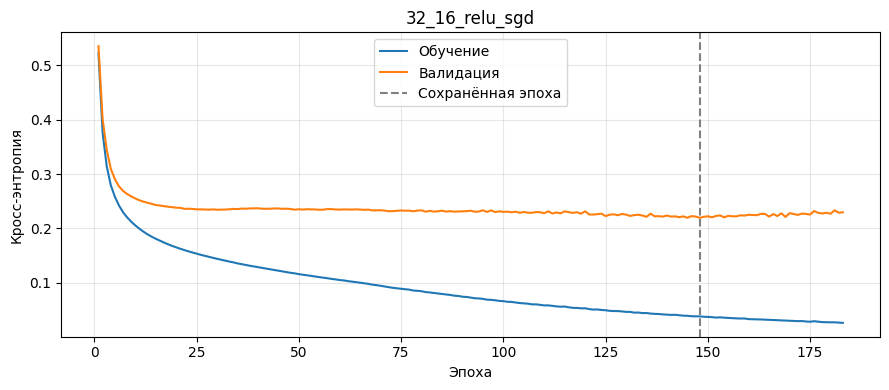

In [15]:
classification_runs = {}
validation_rows = []

for config in configs:
    result = train_model(
        config,
        Xc_train,
        yc_train,
        Xc_val,
        yc_val,
        task="classification"
    )

    name = config["name"]
    classification_runs[name] = result

    model = result["model"]
    prediction = model.predict(Xc_val)

    validation_rows.append({
        "model": name,
        "parameters": result["parameters"],
        "best_epoch": result["best_epoch"],
        "epochs_run": len(result["history"]),
        "val_balanced_accuracy": balanced_accuracy_score(
            yc_val,
            prediction
        ),
        "val_log_loss": log_loss(
            yc_val,
            model.predict_proba(Xc_val),
            labels=classes
        )
    })

    print(name, "— обучение завершено")

validation_c = pd.DataFrame(validation_rows)

display(validation_c.round(4))

max_score = validation_c["val_balanced_accuracy"].max()

candidates = validation_c[
    validation_c["val_balanced_accuracy"] >= max_score - 0.01
]

best_c_name = candidates.sort_values(
    ["parameters", "val_log_loss"]
).iloc[0]["model"]

best_c = classification_runs[best_c_name]["model"]

print("Выбран классификатор:", best_c_name)

plot_training(
    classification_runs[best_c_name],
    best_c_name,
    "Кросс-энтропия"
)

In [16]:
class_rows = []
summary_rows = []

for name, result in classification_runs.items():
    model = result["model"]

    prediction = model.predict(Xc_test)
    probabilities = model.predict_proba(Xc_test)

    for j, label in enumerate(model.classes_):
        true_binary = (yc_test == label)
        pred_binary = (prediction == label)

        class_rows.append({
            "model": name,
            "class": class_names[label],
            "support": int(true_binary.sum()),
            "Precision": precision_score(
                true_binary,
                pred_binary,
                zero_division=0
            ),
            "Recall": recall_score(
                true_binary,
                pred_binary,
                zero_division=0
            ),
            "Weighted Accuracy OvR": balanced_accuracy_score(
                true_binary,
                pred_binary
            ),
            "AUC OvR": roc_auc_score(
                true_binary,
                probabilities[:, j]
            )
        })

    summary_rows.append({
        "model": name,
        "Accuracy": accuracy_score(yc_test, prediction),
        "Weighted Accuracy": balanced_accuracy_score(
            yc_test,
            prediction
        ),
        "Precision macro": precision_score(
            yc_test,
            prediction,
            average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            yc_test,
            prediction,
            average="macro",
            zero_division=0
        ),
        "AUC macro": roc_auc_score(
            yc_test,
            probabilities,
            multi_class="ovr",
            average="macro",
            labels=model.classes_
        )
    })

class_metrics = pd.DataFrame(class_rows)
classification_metrics = pd.DataFrame(summary_rows).set_index("model")

print("Метрики по каждому классу:")
display(class_metrics.round(4))

print("Общие метрики:")
display(classification_metrics.round(4))

Метрики по каждому классу:


,model,class,support,Precision,Recall,Weighted Accuracy OvR,AUC OvR
0,16_relu_adam,Норма,247,0.9440,0.9555,0.8777,0.9744
1,16_relu_adam,Подозрительное,44,0.7000,0.6364,0.7962,0.9501
2,16_relu_adam,Патологическое,26,0.8148,0.8462,0.9145,0.9922
3,32_relu_adam,Норма,247,0.9605,0.9838,0.9205,0.9861
4,32_relu_adam,Подозрительное,44,0.8378,0.7045,0.8413,0.9681
5,32_relu_adam,Патологическое,26,0.8519,0.8846,0.9354,0.9939
6,64_32_relu_adam,Норма,247,0.9569,0.9879,0.9154,0.9848
7,64_32_relu_adam,Подозрительное,44,0.8788,0.6591,0.8222,0.9700
8,64_32_relu_adam,Патологическое,26,0.8621,0.9615,0.9739,0.9974
9,32_16_tanh_adam,Норма,247,0.9486,0.9717,0.8930,0.9817


Общие метрики:


,Accuracy,Weighted Accuracy,Precision macro,Recall macro,AUC macro
model,,,,,
16_relu_adam,0.9022,0.8127,0.8196,0.8127,0.9723
32_relu_adam,0.9369,0.8577,0.8834,0.8577,0.9827
64_32_relu_adam,0.9401,0.8695,0.8992,0.8695,0.9841
32_16_tanh_adam,0.9211,0.8385,0.8585,0.8385,0.9821
32_16_relu_sgd,0.9274,0.8474,0.8717,0.8474,0.9771
64_32_16_relu_adam,0.9148,0.8099,0.8532,0.8099,0.9762


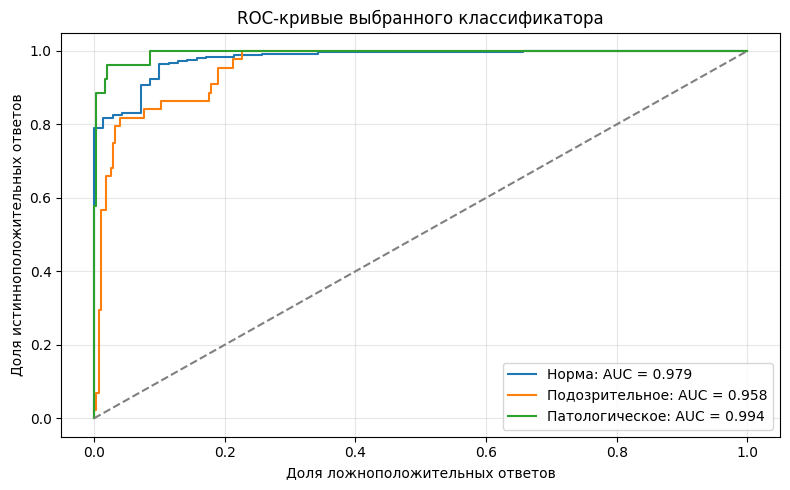

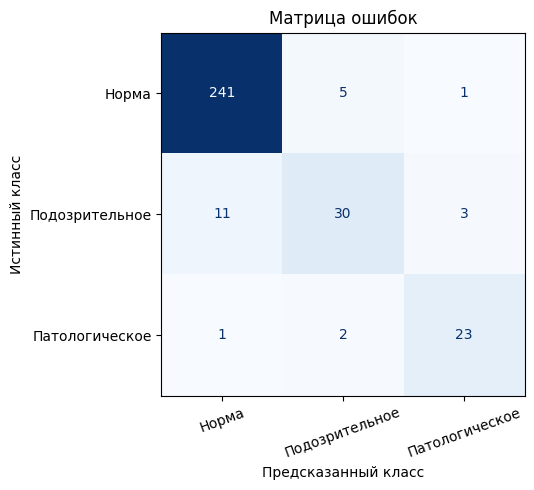

In [17]:
probabilities = best_c.predict_proba(Xc_test)
prediction = best_c.predict(Xc_test)

plt.figure(figsize=(8, 5))

for j, label in enumerate(best_c.classes_):
    true_binary = (yc_test == label).astype(int)

    fpr, tpr, thresholds = roc_curve(
        true_binary,
        probabilities[:, j]
    )

    auc_value = roc_auc_score(
        true_binary,
        probabilities[:, j]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[label]}: AUC = {auc_value:.3f}"
    )

plt.plot([0, 1], [0, 1], "--", color="gray")

plt.title("ROC-кривые выбранного классификатора")
plt.xlabel("Доля ложноположительных ответов")
plt.ylabel("Доля истинноположительных ответов")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    yc_test,
    prediction,
    labels=classes,
    display_labels=[class_names[label] for label in classes],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Матрица ошибок")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.tick_params(axis="x", labelrotation=20)

plt.tight_layout()
plt.show()

Размер таблицы: (731, 16)
Количество пропусков: 0
Повторяющиеся даты: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000,211.166,1.000,183.500,366.000,548.500,731.000
season,731.0,2.497,1.111,1.000,2.000,3.000,3.000,4.000
yr,731.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000
mnth,731.0,6.520,3.452,1.000,4.000,7.000,10.000,12.000
holiday,731.0,0.029,0.167,0.000,0.000,0.000,0.000,1.000
weekday,731.0,2.997,2.005,0.000,1.000,3.000,5.000,6.000
workingday,731.0,0.684,0.465,0.000,0.000,1.000,1.000,1.000
weathersit,731.0,1.395,0.545,1.000,1.000,1.000,2.000,3.000
temp,731.0,0.495,0.183,0.059,0.337,0.498,0.655,0.862
atemp,731.0,0.474,0.163,0.079,0.338,0.487,0.609,0.841


Обучение: (511, 35)
Валидация: (110, 35)
Тест: (110, 35)


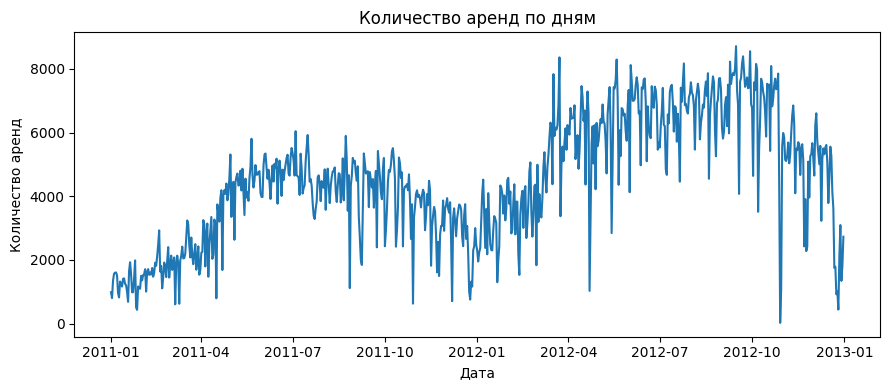

In [18]:
bike = pd.read_csv("day.csv")

print("Размер таблицы:", bike.shape)
print("Количество пропусков:", bike.isna().sum().sum())
print("Повторяющиеся даты:", bike["dteday"].duplicated().sum())

display(bike.head())
display(bike.describe().T.round(3))

assert not bike["dteday"].duplicated().any()
assert (bike["casual"] + bike["registered"] == bike["cnt"]).all()

dates = pd.to_datetime(bike["dteday"])

X = bike.drop(
    columns=["cnt", "casual", "registered", "instant", "dteday"]
).copy()

y = bike["cnt"].astype(float)

# Представляем положение дня в годовом цикле.
days_in_year = np.where(dates.dt.is_leap_year, 366, 365)

X["day_sin"] = np.sin(
    2 * np.pi * (dates.dt.dayofyear - 1) / days_in_year
)

X["day_cos"] = np.cos(
    2 * np.pi * (dates.dt.dayofyear - 1) / days_in_year
)

numeric_columns = [
    "temp", "atemp", "hum", "windspeed",
    "day_sin", "day_cos"
]

categorical_columns = [
    "season", "mnth", "weekday", "weathersit"
]

binary_columns = [
    "yr", "holiday", "workingday"
]

Xr_train, Xr_rest, yr_train, yr_rest = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED
)

Xr_val, Xr_test, yr_val, yr_test = train_test_split(
    Xr_rest,
    yr_rest,
    test_size=0.50,
    random_state=SEED
)

preprocessor_r = ColumnTransformer([
    (
        "numeric",
        make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ),
        numeric_columns
    ),
    (
        "categorical",
        make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        ),
        categorical_columns
    ),
    (
        "binary",
        SimpleImputer(strategy="most_frequent"),
        binary_columns
    )
])

Xr_train = preprocessor_r.fit_transform(Xr_train)
Xr_val = preprocessor_r.transform(Xr_val)
Xr_test = preprocessor_r.transform(Xr_test)

yr_train = yr_train.to_numpy()
yr_val = yr_val.to_numpy()
yr_test = yr_test.to_numpy()

# Масштабируем цель только по обучающим значениям.
target_scaler = StandardScaler()

yr_train_scaled = target_scaler.fit_transform(
    yr_train.reshape(-1, 1)
).ravel()

yr_val_scaled = target_scaler.transform(
    yr_val.reshape(-1, 1)
).ravel()

print("Обучение:", Xr_train.shape)
print("Валидация:", Xr_val.shape)
print("Тест:", Xr_test.shape)

plt.plot(dates, bike["cnt"])
plt.title("Количество аренд по дням")
plt.xlabel("Дата")
plt.ylabel("Количество аренд")
plt.tight_layout()
plt.show()

16_relu_adam — обучение завершено
32_relu_adam — обучение завершено
64_32_relu_adam — обучение завершено
32_16_tanh_adam — обучение завершено
32_16_relu_sgd — обучение завершено
64_32_16_relu_adam — обучение завершено


,model,parameters,best_epoch,epochs_run,val_MSE,val_MAE,val_R2
0,16_relu_adam,593,148,183,432788.0107,464.4272,0.8959
1,32_relu_adam,1185,113,148,361060.8594,437.4257,0.9131
2,64_32_relu_adam,4417,44,79,329465.5395,422.5787,0.9207
3,32_16_tanh_adam,1697,108,143,300456.8360,386.8078,0.9277
4,32_16_relu_sgd,1697,68,103,375458.0851,431.3481,0.9097
5,64_32_16_relu_adam,4929,30,65,295713.4057,394.9731,0.9289


Выбран регрессор: 32_16_tanh_adam


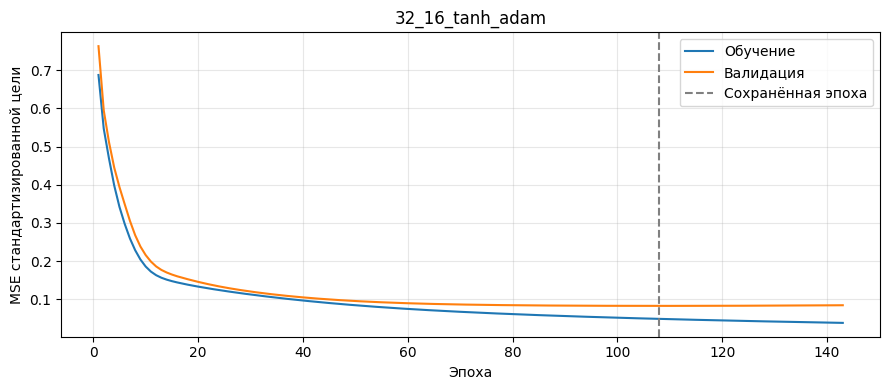

In [19]:
def predict_rental(model, X):
    prediction_scaled = model.predict(X)

    return target_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    ).ravel()


regression_runs = {}
validation_rows = []

for config in configs:
    result = train_model(
        config,
        Xr_train,
        yr_train_scaled,
        Xr_val,
        yr_val_scaled,
        task="regression"
    )

    name = config["name"]
    regression_runs[name] = result

    prediction = predict_rental(
        result["model"],
        Xr_val
    )

    validation_rows.append({
        "model": name,
        "parameters": result["parameters"],
        "best_epoch": result["best_epoch"],
        "epochs_run": len(result["history"]),
        "val_MSE": mean_squared_error(yr_val, prediction),
        "val_MAE": mean_absolute_error(yr_val, prediction),
        "val_R2": r2_score(yr_val, prediction)
    })

    print(name, "— обучение завершено")

validation_r = pd.DataFrame(validation_rows)

display(validation_r.round(4))

min_mse = validation_r["val_MSE"].min()

candidates = validation_r[
    validation_r["val_MSE"] <= min_mse * 1.02
]

best_r_name = candidates.sort_values(
    ["parameters", "val_MSE"]
).iloc[0]["model"]

best_r = regression_runs[best_r_name]["model"]

print("Выбран регрессор:", best_r_name)

plot_training(
    regression_runs[best_r_name],
    best_r_name,
    "MSE стандартизированной цели"
)

In [20]:
regression_rows = []

for name, result in regression_runs.items():
    prediction = predict_rental(
        result["model"],
        Xr_test
    )

    regression_rows.append({
        "model": name,
        "MSE": mean_squared_error(yr_test, prediction),
        "MAE": mean_absolute_error(yr_test, prediction),
        "R2": r2_score(yr_test, prediction)
    })

baseline_prediction = np.full(
    len(yr_test),
    yr_train.mean()
)

regression_rows.append({
    "model": "Среднее обучающей выборки",
    "MSE": mean_squared_error(yr_test, baseline_prediction),
    "MAE": mean_absolute_error(yr_test, baseline_prediction),
    "R2": r2_score(yr_test, baseline_prediction)
})

regression_metrics = pd.DataFrame(
    regression_rows
).set_index("model")

display(regression_metrics.round(4))

,MSE,MAE,R2
model,,,
16_relu_adam,4.550567e+05,497.8232,0.8802
32_relu_adam,4.532304e+05,508.0430,0.8807
64_32_relu_adam,5.056228e+05,513.3417,0.8669
32_16_tanh_adam,4.287754e+05,473.0087,0.8871
32_16_relu_sgd,3.766052e+05,446.2605,0.9009
64_32_16_relu_adam,4.021040e+05,460.4639,0.8942
Среднее обучающей выборки,3.821083e+06,1632.5334,-0.0057


In [21]:
print("КЛАССИФИКАТОР")
print("Выбранная модель:", best_c_name)

display(
    classification_metrics.loc[[best_c_name]].round(4)
)

train_accuracy = balanced_accuracy_score(
    yc_train,
    best_c.predict(Xc_train)
)

val_accuracy = balanced_accuracy_score(
    yc_val,
    best_c.predict(Xc_val)
)

print(f"Balanced accuracy на обучении: {train_accuracy:.3f}")
print(f"Balanced accuracy на валидации: {val_accuracy:.3f}")
print(f"Разрыв: {train_accuracy - val_accuracy:.3f}")

selected_classes = class_metrics[
    class_metrics["model"] == best_c_name
]

weakest_class = selected_classes.sort_values(
    "Recall"
).iloc[0]

print(
    "Самый низкий Recall:",
    weakest_class["class"],
    f"({weakest_class['Recall']:.3f})"
)

print("\nРЕГРЕССОР")
print("Выбранная модель:", best_r_name)

display(
    regression_metrics.loc[[best_r_name]].round(4)
)

train_r2 = r2_score(
    yr_train,
    predict_rental(best_r, Xr_train)
)

val_r2 = r2_score(
    yr_val,
    predict_rental(best_r, Xr_val)
)

print(f"R² на обучении: {train_r2:.3f}")
print(f"R² на валидации: {val_r2:.3f}")
print(f"Разрыв: {train_r2 - val_r2:.3f}")

КЛАССИФИКАТОР
Выбранная модель: 32_16_relu_sgd


,Accuracy,Weighted Accuracy,Precision macro,Recall macro,AUC macro
model,,,,,
32_16_relu_sgd,0.9274,0.8474,0.8717,0.8474,0.9771


Balanced accuracy на обучении: 0.977
Balanced accuracy на валидации: 0.824
Разрыв: 0.152
Самый низкий Recall: Подозрительное (0.682)

РЕГРЕССОР
Выбранная модель: 32_16_tanh_adam


,MSE,MAE,R2
model,,,
32_16_tanh_adam,428775.4036,473.0087,0.8871


R² на обучении: 0.952
R² на валидации: 0.928
Разрыв: 0.024
